In [1]:
%matplotlib inline

# RGB Vegetation Indices and Canopy Cover

A consumer drone has no near-infrared band, but its red, green and blue channels still
separate plants from soil and water. When the camera also records near-infrared, the same
idea becomes a ground-cover fraction read from the bare-soil line.


## Overview

Visible-band indices such as VARI, TGI and Excess Green
(ExG) are the workhorses of low-cost phenotyping. This notebook computes them with
`rs.uav.vegetation_indices`, reproduces the LUMS `make_tgi_vari.py` script, turns an index
into a vegetation mask and canopy cover with `rs.uav.canopy_cover`, and builds a first growth
curve: rice canopy cover over all 11 public LUMS dates. The last section changes sensor. A
five-band wheat mosaic from Barisal, Bangladesh, has red and near-infrared, so ground cover
is the perpendicular vegetation index divided by its value at full canopy
(Maas and Rajan, 2008), from `rs.uav.bare_soil_line` and `rs.uav.cover_layers`.


## Core concepts

### Learning objectives

1. Compute VARI, TGI, ExG, ExGR, GLI, NGRDI and CIVE and know what each emphasises.
2. Reproduce a published script with GeoLattice and check the numbers match.
3. Understand chromatic normalisation and how illumination changes each index.
4. Threshold an index with Otsu's method to get a vegetation mask and canopy cover.
5. Build a multi-date canopy cover curve and spot when a method breaks down.
6. Fit a bare-soil line to red and NIR digital numbers, convert it to ground cover and WDVI,
   and summarise cover inside field plots.

### Data

| Data | Type |
|---|---|
| LUMS rice frames, 11 dates from 22 Aug to 3 Oct 2025, 10 frames each (`Data/08_remote_sensing/08_04_uav/infrastructure-free-uav-phenotyping`) | **Real** (CC BY 4.0) |
| Barisal wheat, five-band UAV GeoTIFF on 12 Feb, 27 Feb and 12 Mar 2015, plus nine plot polygons (`Data/08_remote_sensing/08_04_uav/UAV_BD`) | **Real** (STARS project) |

### Contents

1. Setup
2. The indices
3. Reproducing `make_tgi_vari.py`
4. Brightness and chromatic normalisation
5. Vegetation mask and canopy cover
6. A season of canopy cover
7. Green ground cover from red and NIR
8. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [2]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice.rsense as rs  # GeoLattice remote sensing (rs.uav = drone tools)

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_04_uav")
LUMS = DATA / "infrastructure-free-uav-phenotyping"
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

## The indices

With R, G, B scaled to 0-1:

| Index | Formula | Notes |
|---|---|---|
| VARI | $(G-R)/(G+R-B)$ | Visible Atmospherically Resistant Index; ratio, so insensitive to brightness |
| TGI | $-0.5\,[190(R-G) - 120(R-B)]$ | Triangular Greenness Index; tracks chlorophyll |
| TGI (LUMS) | $(G - 0.39R - 0.61B)/\max(R,G,B)$ | Max-normalised variant used in `make_tgi_vari.py` (`TGI_MAXNORM`) |
| ExG | $2G - R - B$ | Excess Green; simple, strong plant/soil contrast |
| ExGR | $ExG - (1.4R - G)$ | ExG minus Excess Red; zero is a natural threshold |
| GLI | $(2G-R-B)/(2G+R+B)$ | Green Leaf Index |
| NGRDI | $(G-R)/(G+R)$ | Normalised green-red difference |
| CIVE | $0.441R - 0.811G + 0.385B + 18.787$ | Colour Index of Vegetation Extraction; **lower** = greener |


In [3]:
frame_path = sorted((LUMS / "2025-08-22").glob("*.png"))[0]
img = rs.uav.read_frame(frame_path, max_dim=1920)  # (band, y, x), 0-1
vi = rs.uav.vegetation_indices(img, ["VARI", "TGI", "TGI_MAXNORM", "ExG", "ExGR", "GLI", "NGRDI", "CIVE"])
vi

<xarray.Dataset> Size: 66MB
Dimensions:      (y: 1080, x: 1920)
Coordinates:
  * y            (y) float64 9kB -0.5 -1.5 -2.5 ... -1.078e+03 -1.08e+03
  * x            (x) float64 15kB 0.5 1.5 2.5 ... 1.918e+03 1.918e+03 1.92e+03
Data variables:
    VARI         (y, x) float32 8MB 0.1111 0.129 0.121 ... -0.08811 -0.08811
    TGI          (y, x) float32 8MB 13.92 13.96 13.59 ... 1.255 1.255 1.255
    TGI_MAXNORM  (y, x) float32 8MB 0.4109 0.4082 0.3971 ... 0.01224 0.01224
    ExG          (y, x) float32 8MB 0.2549 0.2588 0.251 ... -0.01176 -0.01176
    ExGR         (y, x) float32 8MB 0.2216 0.2345 0.2216 ... -0.3373 -0.3373
    GLI          (y, x) float32 8MB 0.2234 0.2245 0.2162 ... -0.003932 -0.003932
    NGRDI        (y, x) float32 8MB 0.08537 0.09756 0.09091 ... -0.05 -0.05
    CIVE         (y, x) float32 8MB 18.69 18.69 18.69 ... 18.81 18.81 18.81
Attributes:
    source:    ../../../../Data/08_remote_sensing/08_04_uav/infrastructure-fr...
    gsd_m:     None
    units_xy:  px

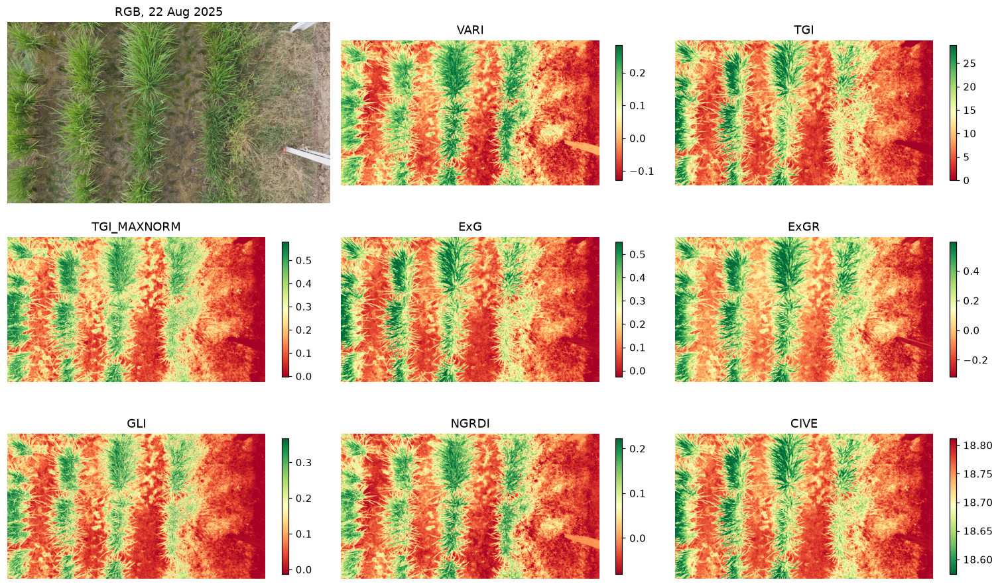

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(14, 8.5))
axes[0, 0].imshow(rs.uav.to_rgb_array(img)); axes[0, 0].set_title("RGB, 22 Aug 2025")
for ax, name in zip(axes.flat[1:], vi.data_vars):
    v = vi[name].values
    lo, hi = np.nanpercentile(v, [2, 98])
    im = ax.imshow(v, cmap="RdYlGn_r" if name == "CIVE" else "RdYlGn", vmin=lo, vmax=hi)
    ax.set_title(name); plt.colorbar(im, ax=ax, shrink=0.7)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

## Reproducing `make_tgi_vari.py`

The LUMS script (in `code/vegetation_indices/`) reads an orthomosaic PNG, computes VARI and
the max-normalised TGI in column chunks, and replaces zero denominators with 1e-6. The same
arithmetic in plain NumPy:


In [5]:
rgb = rs.uav.to_rgb_array(img).astype(np.float32)  # (rows, cols, 3), 0-1
R, G, B = rgb[..., 0], rgb[..., 1], rgb[..., 2]
den = G + R - B; den[den == 0] = 1e-6
vari_lums = (G - R) / den
mx = np.maximum(np.maximum(R, G), B); mx[mx == 0] = 1e-6
tgi_lums = (G - 0.39 * R - 0.61 * B) / mx

cmp = pd.DataFrame({
    "index": ["VARI", "TGI_MAXNORM"],
    "max_abs_diff": [np.nanmax(np.abs(vari_lums - vi.VARI.values)), np.nanmax(np.abs(tgi_lums - vi.TGI_MAXNORM.values))],
    "pct_pixels_differing_>1e-4": [100 * np.mean(np.abs(vari_lums - vi.VARI.values) > 1e-4),
                                   100 * np.mean(np.abs(tgi_lums - vi.TGI_MAXNORM.values) > 1e-4)],
})
cmp

,index,max_abs_diff,pct_pixels_differing_>1e-4
0,VARI,0.0,0.0
1,TGI_MAXNORM,0.0,0.0


The two agree exactly on this frame. They can differ only where the VARI denominator
$G + R - B$ is exactly zero: the script substitutes 1e-6 there (giving huge values). VARI is
unstable wherever blue is high relative to red and green (glare on water, white objects), so
its histogram has long tails; the script clips nothing, and the histograms below clip to the
1st-99th percentile for display.


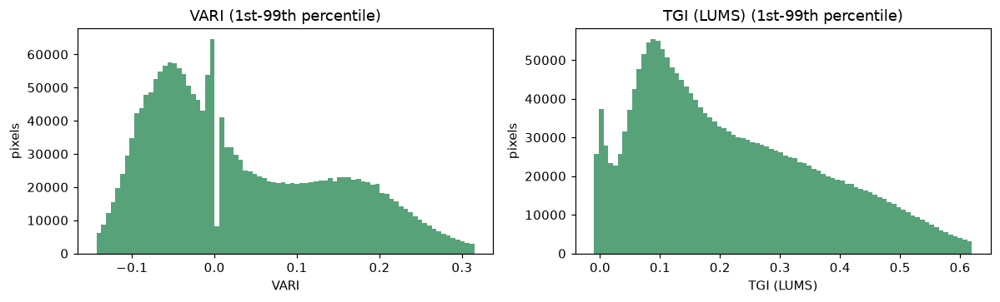

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (name, v) in zip(axes, [("VARI", vi.VARI.values), ("TGI (LUMS)", vi.TGI_MAXNORM.values)]):
    v = v[np.isfinite(v)]
    lo, hi = np.percentile(v, [1, 99])
    ax.hist(v[(v > lo) & (v < hi)], bins=80, color="seagreen", alpha=0.8)
    ax.set(title=f"{name} (1st-99th percentile)", xlabel=name, ylabel="pixels")
plt.tight_layout(); plt.show()

## Brightness and chromatic normalisation

Clouds passing over during a flight change brightness between frames. Ratio indices (VARI,
NGRDI, GLI, TGI_MAXNORM) cancel a uniform scaling; difference indices (ExG, ExGR, TGI) scale
with it. `normalize=True` first converts to chromatic coordinates $r = R/(R+G+B)$ etc., which
makes ExG brightness-invariant too.


In [7]:
rows = []
for factor in [0.6, 0.8, 1.0, 1.2]:
    dim = (img * factor).clip(0, 1)
    raw = rs.uav.vegetation_indices(dim, ["ExG", "VARI", "TGI"])
    nrm = rs.uav.vegetation_indices(dim, ["ExG"], normalize=True)
    rows.append({"brightness x": factor, "ExG mean": float(raw.ExG.mean()), "ExG (chromatic) mean": float(nrm.ExG.mean()),
                 "VARI p90": float(raw.VARI.quantile(0.9)), "TGI mean": float(raw.TGI.mean())})
pd.DataFrame(rows).round(4)

,brightness x,ExG mean,ExG (chromatic) mean,VARI p90,TGI mean
0,0.6,0.1068,0.1637,0.2021,6.0812
1,0.8,0.1424,0.1637,0.2021,8.1083
2,1.0,0.1780,0.1637,0.2021,10.1353
3,1.2,0.2137,0.1637,0.2021,12.1698


## Vegetation mask and canopy cover

`rs.uav.canopy_cover(index)` thresholds an index (Otsu's method by default, which picks the
cut that best separates two modes of the histogram) and returns the mask and the cover
fraction. Different indices give slightly different answers; CIVE is inverted (lower is
greener), so it is negated first.


index,ExG,ExGR,VARI,GLI,NGRDI,CIVE
canopy_cover,0.314,0.34,0.357,0.31,0.326,0.316


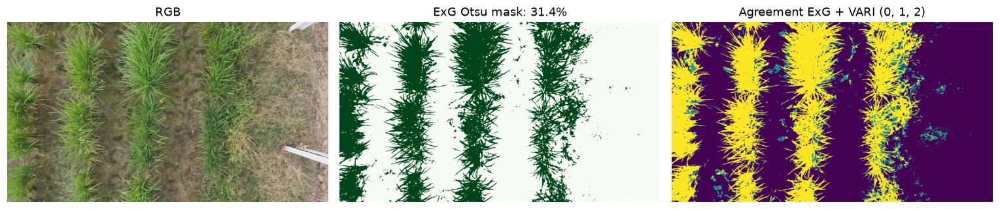

In [8]:
cover_rows, masks = [], {}
for name in ["ExG", "ExGR", "VARI", "GLI", "NGRDI", "CIVE"]:
    v = -vi[name] if name == "CIVE" else vi[name]
    if name == "VARI":
        v = v.clip(-1, 1)  # tame the unstable tails before Otsu
    mask, cover = rs.uav.canopy_cover(v)
    masks[name] = mask
    cover_rows.append({"index": name, "canopy_cover": cover})
covers = pd.DataFrame(cover_rows).set_index("index")
display(covers.round(3).T)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].imshow(rs.uav.to_rgb_array(img)); axes[0].set_title("RGB")
axes[1].imshow(masks["ExG"], cmap="Greens"); axes[1].set_title(f"ExG Otsu mask: {covers.loc['ExG', 'canopy_cover']:.1%}")
agree = masks["ExG"].values.astype(int) + masks["VARI"].values.astype(int)
axes[2].imshow(agree, cmap="viridis"); axes[2].set_title("Agreement ExG + VARI (0, 1, 2)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## A season of canopy cover

The cell below computes ExG canopy cover for all 110 public frames. `rs.uav.trait_table`
applies a function to each catalogue row; frames are read at `max_dim=1280` for speed (cover
is a fraction, so it barely changes with resolution).


In [9]:
cat = rs.uav.build_catalog(LUMS.parent)
cat = cat[cat.dataset.str.startswith("infra")].assign(crop="rice")

def cover_traits(image):
    """ExG canopy cover with Otsu and with a fixed threshold."""
    exg = rs.uav.vegetation_indices(image, "ExG")
    _, otsu = rs.uav.canopy_cover(exg)
    _, fixed = rs.uav.canopy_cover(exg, threshold=0.10, method="fixed")
    return {"cover_otsu": otsu, "cover_fixed_0.10": fixed}

traits = rs.uav.trait_table(cat, cover_traits, max_dim=1280)
per_date = rs.uav.summarize_dates(traits, ["cover_otsu", "cover_fixed_0.10"])
per_date.round(3)

,crop,date,cover_otsu_mean,cover_otsu_std,cover_otsu_count,cover_fixed_0.10_mean,cover_fixed_0.10_std,cover_fixed_0.10_count
0,rice,2025-08-22,0.425,0.122,10,0.732,0.158,10
1,rice,2025-08-28,0.351,0.066,10,0.648,0.114,10
2,rice,2025-09-04,0.449,0.126,10,0.655,0.165,10
3,rice,2025-09-05,0.413,0.035,10,0.717,0.072,10
4,rice,2025-09-09,0.525,0.075,10,0.765,0.131,10
5,rice,2025-09-12,0.537,0.063,10,0.849,0.103,10
6,rice,2025-09-17,0.536,0.062,10,0.818,0.131,10
7,rice,2025-09-19,0.533,0.033,10,0.852,0.036,10
8,rice,2025-09-26,0.527,0.040,10,0.868,0.069,10
9,rice,2025-10-01,0.515,0.041,10,0.861,0.064,10


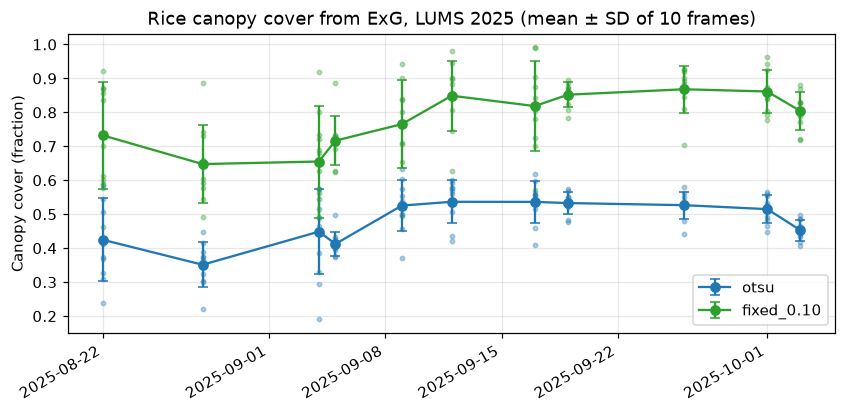

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
for col, c in [("cover_otsu", "C0"), ("cover_fixed_0.10", "C2")]:
    ax.errorbar(per_date.date, per_date[f"{col}_mean"], yerr=per_date[f"{col}_std"], fmt="o-", color=c,
                capsize=3, label=col.replace("cover_", ""))
    ax.scatter(traits.date, traits[col], color=c, s=8, alpha=0.35)
ax.set(ylabel="Canopy cover (fraction)", title="Rice canopy cover from ExG, LUMS 2025 (mean ± SD of 10 frames)")
ax.legend(); ax.grid(alpha=0.3); fig.autofmt_xdate(); plt.show()

The two curves disagree by 30 to 45 percentage points, and the frames below show why
neither is right all season:

* **Otsu needs two modes.** On 22 August the histogram has a plant mode and a soil mode, and
  Otsu cover (about 31 % on the frame in Section 5) matches what the eye sees. Once the
  canopy closes in September there is almost no soil left, so the histogram has one broad
  mode and Otsu splits **sunlit from shaded leaves** instead. Its cover stalls near 50 %
  while the field is nearly fully covered, and it drops again on 3 October.
* **A fixed threshold depends on the background.** ExG = 0.10 captures the closed canopy well
  (about 96 % on 1 October) but early in the season it also counts the greenish, weedy soil
  between rows, overestimating cover.
* The ten frames per date come from **different parts of the field**, so the error bars mix
  real spatial variation with the date effect.

In practice, pick the threshold per growth stage, calibrate it once on frames with soil
visible and freeze it, or replace thresholding with a trained classifier (notebook 09_04_08).


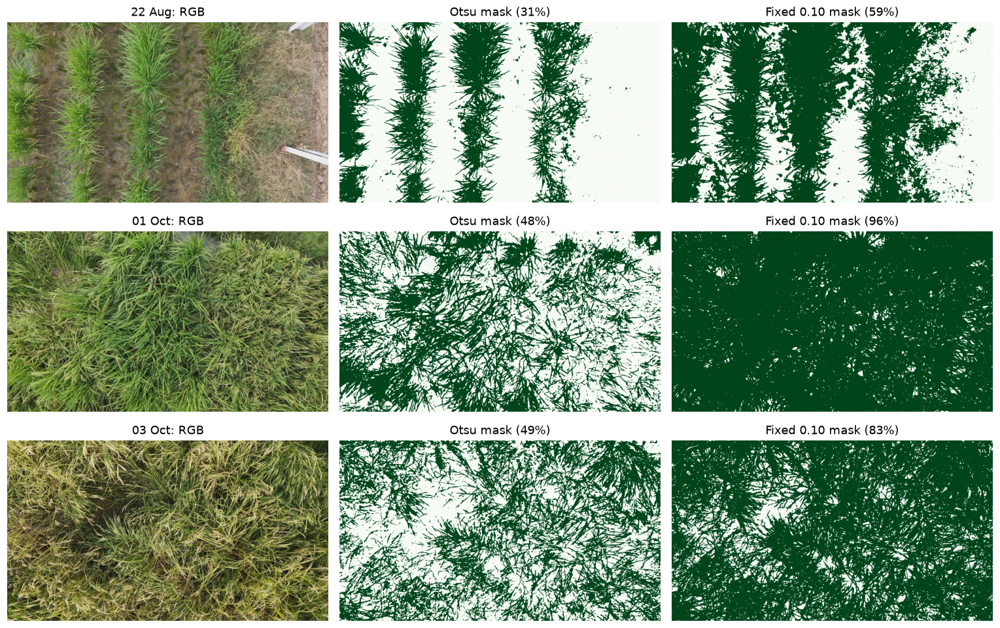

In [11]:
late = pd.concat([traits[traits.date == traits.date.min()].head(1),
                  traits.sort_values("date").groupby("date").head(1).tail(2)])
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for row, (_, r) in zip(axes, late.iterrows()):
    im = rs.uav.read_frame(r.path, max_dim=1280)
    exg = rs.uav.vegetation_indices(im, "ExG")
    m_otsu, c_otsu = rs.uav.canopy_cover(exg)
    m_fix, c_fix = rs.uav.canopy_cover(exg, threshold=0.10, method="fixed")
    row[0].imshow(rs.uav.to_rgb_array(im)); row[0].set_title(f"{r.date:%d %b}: RGB")
    row[1].imshow(m_otsu, cmap="Greens"); row[1].set_title(f"Otsu mask ({c_otsu:.0%})")
    row[2].imshow(m_fix, cmap="Greens"); row[2].set_title(f"Fixed 0.10 mask ({c_fix:.0%})")
    for a in row: a.axis("off")
plt.tight_layout(); plt.show()

traits.to_csv(OUT / "rice_canopy_cover_frames.csv", index=False)

## Green ground cover from red and NIR

The indices above work from red, green and blue. This section uses red and near-infrared on a wheat field at Barisal, Bangladesh, and follows `uav-ground-cover.Rmd` and `uav-ground-cover.py`. The soil line is `rs.uav.bare_soil_line`. PVI, ground cover and WDVI come from `rs.uav.cover_layers`.

Ground cover (fCover) is the fraction of the ground hidden by green leaves. On a crop it tracks canopy closure, and it is also a clue to erosion and early irrigation: a closed canopy shades the soil and intercepts rain. Maas and Rajan (2008) estimate that fraction from digital numbers. In red-NIR space, bare soil falls on a straight line

$$
\mathrm{NIR} = a_1\,\mathrm{Red} + a_0
$$

Leaves sit off that line, because they reflect NIR and absorb red. The perpendicular vegetation index (PVI) is the distance from the pixel to the line. Ground cover is that distance divided by the distance of a full canopy:

$$
\mathrm{PVI} = \frac{\mathrm{NIR} - a_1\,\mathrm{Red} - a_0}{\sqrt{1+a_1^2}}, \qquad
\mathrm{GC} = \frac{\mathrm{PVI}}{\mathrm{PVI_{FC}}}
$$

The weighted difference vegetation index uses the same slope without the perpendicular term:

$$
\mathrm{WDVI} = \frac{\mathrm{NIR}}{255} - a_1\frac{\mathrm{Red}}{255}
$$

Three mosaics, flown on 12 February, 27 February and 12 March 2015 under the [STARS project](https://www.stars-project.org/en/about-us/the-stars-project/), are in `UAV_BD`, with the nine plot polygons in `plot_bd_wheat.shp`. Each GeoTIFF has five bands and no CRS tag. The plot file is EPSG:32646 and the coordinates match, so the mosaics are read as that CRS. As in the R lesson, band 2 is red, band 3 is green and band 5 is NIR. The values are digital numbers from that camera, so each flight gets its own soil line.


In [12]:
import geopandas as gpd  # plot polygons
from matplotlib.colors import LinearSegmentedColormap
BD = DATA / "UAV_BD"
PLOTS = gpd.read_file(BD / "plot_bd_wheat.shp")
DATES = {
    "2015-02-12": BD / "multi_bwh_mc_20150212.tif",
    "2015-02-27": BD / "multi_bwh_mc_20150227.tif",
    "2015-03-12": BD / "multi_bwh_mc_20150312.tif",
}
# Band order from uav-ground-cover.Rmd: 2 = red, 3 = green, 5 = NIR.
BANDS = ["b1", "red", "green", "b4", "nir"]
MAXVAL = 255  # landsat::BSL drops digital numbers at or above this
ULIMIT = 0.99  # top fraction of the NIR/red ratio used to find full canopy
GC_CMAP = LinearSegmentedColormap.from_list(
    "gc", ["#FF0000", "#FFFF00", "#00FF00", "#008B00"]
)

def load_stack(path):
    """Read one mosaic and attach the plot CRS (the GeoTIFF has none)."""
    da = rs.read(path, band_names=BANDS, masked=True)
    return da.rio.write_crs(PLOTS.crs)

def stretch_linear(band, quantiles=(0.02, 0.98)):
    """2-98% stretch, the limits RStoolbox uses for stretch='lin'."""
    values = band[np.isfinite(band)]
    lo, hi = np.quantile(values, quantiles)
    if hi == lo:
        hi = lo + 1e-9
    return np.clip((band - lo) / (hi - lo), 0, 1)

stack = load_stack(DATES["2015-02-12"])
print(f"{stack.sizes['y']} rows x {stack.sizes['x']} cols, bands: {', '.join(map(str, stack.band.values))}")
print("CRS", stack.rio.crs)
print("plots", ", ".join(PLOTS.sort_values("ID").Name), "at", PLOTS.Site_name.iloc[0])


703 rows x 601 cols, bands: b1, red, green, b4, nir
CRS EPSG:32646
plots BW1, BW2, BW3, BW4, BW5, BW6, BW7, BW8, BW9 at Barisal


### False-colour composite

NIR goes in the red channel, red in the green channel and green in the blue channel, each stretched from the 2nd to the 98th percentile. Leaves are bright in NIR and dark in the red band, so the plots come out magenta. Paths and bare edges, where NIR is low, come out cyan. The white lines are the nine wheat plots.


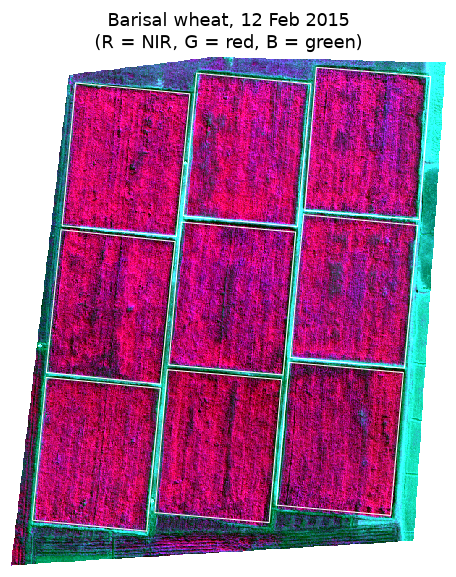

In [13]:
channels = [stretch_linear(stack.sel(band=name).values) for name in ("nir", "red", "green")]
rgb = np.dstack([np.nan_to_num(channel, nan=0.0) for channel in channels])
alpha = np.isfinite(stack.sel(band="nir").values)
rgba = np.dstack([rgb, alpha.astype("float32")])

left, bottom, right, top = stack.rio.bounds()
fig, ax = plt.subplots(figsize=(5, 5.5))
ax.imshow(rgba, extent=(left, right, bottom, top), interpolation="nearest")
PLOTS.boundary.plot(ax=ax, color="white", linewidth=0.7)
ax.set_axis_off()
ax.set_title("Barisal wheat, 12 Feb 2015\n(R = NIR, G = red, B = green)")
plt.tight_layout(); plt.show()


### Bare soil line

NIR plotted against red forms a triangular cloud. The lower edge is soil: both bands rise together as the soil gets brighter. Vegetation leaves that edge toward high NIR and low red.

`rs.uav.bare_soil_line` fits the minimum soil line from `landsat::BSL`. For each integer red value below 255, keep the lowest NIR, then fit a major-axis line (the default in `lmodel2`, which is what `BSL` calls). The full-canopy point is taken from the pixels whose NIR/red ratio is above the 99th percentile. Among those, it is the pixel closest to high NIR and low red. The grey cloud in the figure is a sample of pixels; the line is fit on every finite pixel.


pixels in the fit: 363,544   red levels: 92
a0 = 11.997    a1 = 0.937    R^2 = 0.900
full canopy: red = 6, NIR = 178


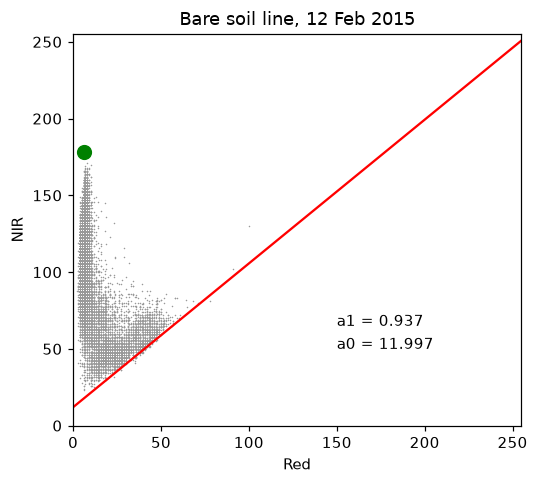

In [14]:
red = stack.sel(band="red")
nir = stack.sel(band="nir")
bsl = rs.uav.bare_soil_line(red, nir, maxval=MAXVAL, ulimit=ULIMIT)
print(f"pixels in the fit: {bsl['n_pixels']:,}   red levels: {bsl['n_levels']}")
print(f"a0 = {bsl['intercept']:.3f}    a1 = {bsl['slope']:.3f}    R^2 = {bsl['r_squared']:.3f}")
print(f"full canopy: red = {bsl['top_red']:.0f}, NIR = {bsl['top_nir']:.0f}")

finite = np.isfinite(red.values) & np.isfinite(nir.values)
xs, ys = red.values[finite].ravel(), nir.values[finite].ravel()
rng = np.random.default_rng(0)
take = rng.choice(xs.size, size=min(20000, xs.size), replace=False)

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(xs[take], ys[take], s=1, c="0.6", linewidths=0, rasterized=True)
line_x = np.array([0.0, MAXVAL])
ax.plot(line_x, bsl["slope"] * line_x + bsl["intercept"], color="red", linewidth=1.5)
ax.scatter([bsl["top_red"]], [bsl["top_nir"]], c="green", s=80, zorder=5)
ax.text(150, 65, f"a1 = {bsl['slope']:.3f}")
ax.text(150, 50, f"a0 = {bsl['intercept']:.3f}")
ax.set_xlim(0, MAXVAL); ax.set_ylim(0, MAXVAL)
ax.set_xlabel("Red"); ax.set_ylabel("NIR")
ax.set_title("Bare soil line, 12 Feb 2015")
plt.tight_layout(); plt.show()


### Perpendicular vegetation index and ground cover

`rs.uav.cover_layers` returns PVI, ground cover and WDVI. PVI below 0 lies on the soil side of the line and is set to 0. PVI above 100 is set to 100, as in the R lesson, and the map shows PVI/100. Ground cover is PVI divided by PVI at the full-canopy point, then clipped to 0-1. WDVI is clipped to the same range. The colours are the red-yellow-green ramp from the original figures.


PVI at full cover = 117.06
GC   min 0.000   mean 0.480   max 0.854
WDVI min 0.000   max 0.704


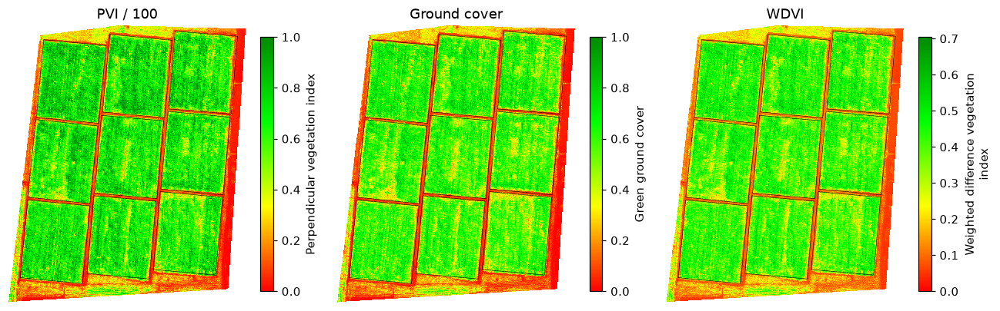

In [15]:
layers = rs.uav.cover_layers(stack, maxval=MAXVAL, ulimit=ULIMIT)
pvi, gc, wdvi = layers.PVI, layers.GC, layers.WDVI
print(f"PVI at full cover = {layers.attrs['pvi_fc']:.2f}")
print(f"GC   min {np.nanmin(gc.values):.3f}   mean {np.nanmean(gc.values):.3f}   max {np.nanmax(gc.values):.3f}")
print(f"WDVI min {np.nanmin(wdvi.values):.3f}   max {np.nanmax(wdvi.values):.3f}")

bd_out = OUT / "uav_bd"
bd_out.mkdir(exist_ok=True)
for name, band in (
    ("pvi", pvi),
    ("pvi_normalized", (pvi / 100).rename("pvi_normalized")),
    ("ground_cover", gc.rename("ground_cover")),
    ("wdvi", wdvi.rename("wdvi")),
):
    rs.write(band, bd_out / f"{name}_20150212.tif")

panels = [
    ((pvi / 100).rename("PVI / 100"), "PVI / 100", None),
    (gc, "Ground cover", (0, 1)),
    (wdvi, "WDVI", None),
]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6))
for ax, (band, title, limits) in zip(axes, panels):
    limits_kw = {} if limits is None else {"vmin": limits[0], "vmax": limits[1]}
    band.plot(ax=ax, cmap=GC_CMAP, add_colorbar=True, cbar_kwargs={"shrink": 0.7}, **limits_kw)
    PLOTS.boundary.plot(ax=ax, color="k", linewidth=0.4)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout(); plt.show()


### Cover inside the plots, on three dates

Each flight keeps its own soil line, because the digital numbers still carry that day's brightness. Mean ground cover inside each wheat plot comes from `rs.zonal_stats`.


2015-02-12  a0 = 11.997  a1 = 0.937  PVI_FC = 117.06  image mean GC = 0.480
2015-02-27  a0 = 16.483  a1 = 0.846  PVI_FC = 77.34  image mean GC = 0.565


2015-03-12  a0 = 13.204  a1 = 0.954  PVI_FC = 92.02  image mean GC = 0.354


date,2015-02-12,2015-02-27,2015-03-12
plot,,,
BW1,0.630,0.683,0.383
BW2,0.592,0.676,0.390
BW3,0.564,0.588,0.296
BW4,0.564,0.617,0.353
BW5,0.566,0.632,0.366
BW6,0.558,0.577,0.334
BW7,0.581,0.590,0.369
BW8,0.565,0.629,0.426
BW9,0.537,0.570,0.372


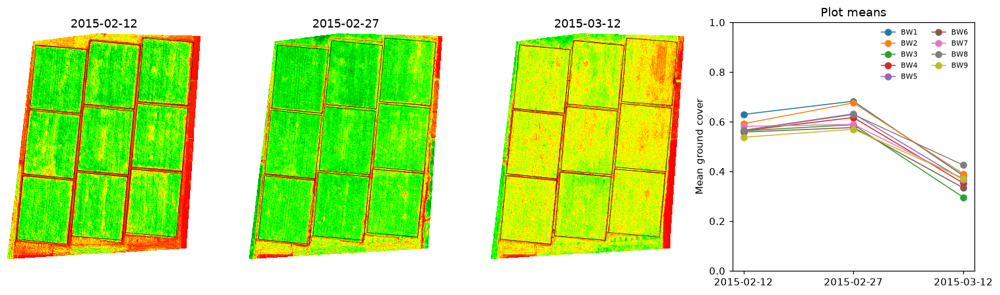

In [16]:
rows, gc_maps = [], {}
for date, path in DATES.items():
    da = load_stack(path)
    layers = rs.uav.cover_layers(da, maxval=MAXVAL, ulimit=ULIMIT)
    gc_da = layers.GC
    gc_maps[date] = gc_da
    zonal = rs.zonal_stats(gc_da, PLOTS, stats=("mean",))
    print(
        f"{date}  a0 = {layers.attrs['intercept']:.3f}  a1 = {layers.attrs['slope']:.3f}  "
        f"PVI_FC = {layers.attrs['pvi_fc']:.2f}  image mean GC = {float(np.nanmean(gc_da.values)):.3f}"
    )
    for rec in zonal.sort_values("ID").itertuples(index=False):
        rows.append({"date": date, "plot": rec.Name, "gc": rec.GC_mean})
    rs.write(gc_da, bd_out / f"ground_cover_{date.replace('-', '')}.tif")

cover = pd.DataFrame(rows)
wide = cover.pivot(index="plot", columns="date", values="gc")
wide = wide.loc[sorted(wide.index, key=lambda name: int(name[2:]))]
display(wide.round(3))

fig, axes = plt.subplots(
    1, 4, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.25]}
)
for ax, date in zip(axes[:3], DATES):
    gc_maps[date].plot(ax=ax, cmap=GC_CMAP, vmin=0, vmax=1, add_colorbar=False)
    PLOTS.boundary.plot(ax=ax, color="k", linewidth=0.45)
    ax.set_title(date)
    ax.set_axis_off()
ax = axes[3]
for name, group in cover.groupby("plot", sort=False):
    ax.plot(group["date"], group["gc"], marker="o", linewidth=1, label=name)
ax.set_ylim(0, 1)
ax.set_ylabel("Mean ground cover")
ax.set_title("Plot means")
ax.legend(ncol=2, fontsize=7, frameon=False)
plt.tight_layout(); plt.show()


On 12 February, PVI at the full-canopy point is about 117. The map clips PVI at 100, so ground cover on that date tops out near 0.85. On 27 February and 12 March the full-canopy point lies below 100, and some pixels reach 1.

The nine plot means sit above the mean of the whole mosaic, which still includes bare ground outside the plots. From 12 February to 27 February every plot rises: the plot means move from about 0.54-0.63 to about 0.57-0.68. On 12 March every plot is lower, about 0.30-0.43. PVI follows green leaves. This late in the wheat season a canopy can lose chlorophyll while the plants are still standing, and those pixels fall back toward the soil line. Read the March drop as less green cover, and check it in the field before treating it as a loss of biomass.


## Summary and exercises

**Key points**

- VARI, TGI, ExG, ExGR, GLI, NGRDI and CIVE separate plants from soil with red, green and
  blue alone.
- Chromatic normalisation reduces the effect of brightness. A panel or an empirical line is
  still what turns DN into reflectance.
- Otsu on ExG gives a vegetation mask and a canopy-cover fraction. After the canopy closes,
  a new threshold every date can drift.
- A threshold frozen on an early date often makes a cleaner season curve.
- With red and NIR, ground cover is PVI divided by PVI at full canopy. Refit the soil line
  on each date: the digital numbers are not reflectance, and soil brightness moves between flights.

**GeoLattice functions used:** `rs.uav.vegetation_indices`, `rs.uav.canopy_cover`, `rs.uav.read_frame`,
`rs.uav.build_catalog`, `rs.uav.trait_table`, `rs.uav.summarize_dates`, `rs.uav.bare_soil_line`, `rs.uav.cover_layers`, `rs.read`,
`rs.write`, `rs.zonal_stats`.

**Exercises**

1. Repeat Section 6 with VARI (clipped to -1..1) instead of ExG. Does VARI suffer from the
   same Otsu problem after canopy closure?
2. Use `normalize=True` for ExG in `cover_traits`. Does the frame-to-frame spread shrink?
3. Find the median Otsu threshold of the 22 Aug frames and apply it, frozen, to every date.
   Does the resulting curve look more plausible than either curve above?
4. Pick a threshold for CIVE by looking at its histogram and compare its cover with ExG.
5. On 12 February, PVI at full cover is above 100, so the clip keeps ground cover below 1.
   Recompute that date without the clip. How far do the plot means move?
6. Hold the 12 February soil line fixed and apply it to 27 February and 12 March. Does the
   March drop in every plot remain?

**References**

- Gitelson, A. A. et al. (2002). Novel algorithms for remote estimation of vegetation
  fraction. *Remote Sensing of Environment*, 80, 76-87 (VARI).
- Hunt, E. R. et al. (2013). A visible band index for remote sensing leaf chlorophyll content
  at the canopy scale. *International Journal of Applied Earth Observation and
  Geoinformation*, 21, 103-112 (TGI).
- Woebbecke, D. M. et al. (1995). Color indices for weed identification under various soil,
  residue, and lighting conditions. *Transactions of the ASAE*, 38, 259-269 (ExG).
- Meyer, G. E. and Neto, J. C. (2008). Verification of color vegetation indices for automated
  crop imaging applications. *Computers and Electronics in Agriculture*, 63, 282-293 (ExGR).
- Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Transactions
  on Systems, Man, and Cybernetics*, 9, 62-66.
- Maas, S. J. and Rajan, N. (2008). Estimating ground cover of field crops using medium-resolution
  multispectral satellite imagery. *Agronomy Journal*, 100, 320-327.
  doi:10.2134/agronj2007.0140.
